# Station subnetwork selection (10–15 stations) for the model

**Core idea.** The model has two layers:

* **Station:** birth–death process. State = bikes docked at the station (0…capacity), *birth* = a bike arrives (rate λ_j(t)), *death* = a bike is picked up (rate μ_i(t)).
* **Subnetwork:** discrete-time Markov chain that moves bikes between stations through the **routing matrix** `P[i, j]` = P(a bike picked up at *i* is returned at *j*).

The two layers are linked by

$$\lambda_j(t) \approx \sum_{i \in S} \mu_i(t)\,P_{ij} \;+\; \lambda_j^{\text{outside}}(t)$$

So we look for subnetworks where the first term explains most of the arrivals. This notebook:

1. Reads the full `cleaned.csv` (EDA output), **all 22 months**, in chunks, accumulating only the matrices it needs (the 35 M trips are never loaded into memory at once).
2. Applies the extra cleaning needed for modelling: impossible durations, stations missing from the GBFS feed and, optionally, weekends (`WEEKDAYS_ONLY`; for now **all days are kept**).
3. Builds the OD matrix and hourly profiles (average per day over the whole period).
4. Detects zones with Louvain and grows candidate subnetworks greedily from every station.
5. Computes for every candidate: **closure**, **irreducibility**, **imbalance**, **capacity pressure**, **censoring signal**, **demographic support** and **stability** between 2025 and 2026.
6. Picks three **contrasting** subnetworks (A: closed and balanced · B: commuter/imbalanced · C: open, hub-like), draws them on a map and exports everything the model needs (λ, μ, P with an "outside" state).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 0. Parameters

Everything that may be discussed in the framing session lives here, so the selection is reproducible and easy to change.

> **Period.** All 22 months are used (Jan-2025 to Oct-2026). The challenge asks to anchor the analysis on a recent month; to restrict it later, just change `PERIOD_START` and `PERIOD_END`.

In [2]:
DATA_PATH = Path("cleaned.csv")        # EDA output
STATIONS_PATH = Path("stations.json")  # GBFS station_information
DIST_PATH = Path("ecobici_distance_matrix_meters.csv")  # OSRM matrix (bicycle profile) from DistanceCalculation.ipynb
OUT_DIR = Path("station_selection")
OUT_DIR.mkdir(exist_ok=True)

PERIOD_START = "2026-09-01"   # full EDA period: 22 months
PERIOD_END = "2026-10-31"
CHUNK_SIZE = 1_000_000        # rows per chunk when reading cleaned.csv (lower it if you run out of RAM)
WEEKDAYS_ONLY = False         # False: keep every day (weekends included). True: drop weekends and holidays (challenge scope)

# Official public holidays (Art. 74 LFT); only removed when WEEKDAYS_ONLY = True
HOLIDAYS = pd.to_datetime([
    "2025-01-01", "2025-02-03", "2025-03-17", "2025-05-01", "2025-09-16", "2025-11-17", "2025-12-25",
    "2026-01-01", "2026-02-02", "2026-03-16", "2026-05-01", "2026-09-16", "2026-11-16", "2026-12-25",
])

# Extra trip cleaning
MIN_DURATION_MIN = 1          # under 1 min: failed undock / error
MAX_DURATION_MIN = 180        # over 3 h: bike not docked properly or atypical case
SAME_STATION_MIN_MIN = 3      # same origin and destination in < 3 min: user returned the bike (a failure, not a trip)

# Candidate construction
K_MIN, K_MAX = 10, 15
K_TARGET = 12                 # size each candidate grows to
MAX_RADIUS_KM = 2.0           # every station within 2 km by road from the seed (contiguous zone)
LOUVAIN_RESOLUTION = 1.0
EDGE_MIN_TRIPS_PER_MONTH = 3  # an arc i->j "exists" if it has >= 3 trips per month on average (irreducibility)

# Time windows
AM_HOURS = range(7, 11)       # 07:00–10:59
PM_HOURS = range(17, 21)      # 17:00–20:59

# Support for the outlier analysis by demographic group
AGE_BINS = [15, 25, 35, 45, 120]
AGE_LABELS = ["16-25", "26-35", "36-45", "46+"]
MIN_TRIPS_PER_GROUP = 300     # minimum internal trips per (gender x age) over the whole period

SEED = 42

## 1. Stations (GBFS)

Coordinates and capacity come from `stations.json`. The station IDs in the CSV (`'027'`, `'271-272'`) match `short_name`. They are normalised to 3 digits in case leading zeros were lost at some step.

In [3]:
def norm_station(s: pd.Series) -> pd.Series:
    s = s.astype(str).str.strip()
    is_num = s.str.fullmatch(r"\d+")
    return s.where(~is_num, s.str.zfill(3))

with open(STATIONS_PATH, encoding="utf-8") as f:
    gbfs = json.load(f)["data"]["stations"]

stations = (
    pd.DataFrame(gbfs)[["short_name", "name", "lat", "lon", "capacity"]]
    .rename(columns={"short_name": "station"})
)
stations["station"] = norm_station(stations["station"])
stations = stations.drop_duplicates("station").set_index("station").sort_index()
print(f"{len(stations)} stations in GBFS · total capacity {stations.capacity.sum():,} docks")
stations.head()

677 stations in GBFS · total capacity 18,183 docks


,name,lat,lon,capacity
station,,,,
001,CE-001 Río Sena-Río Balsas,19.433785,-99.167987,35
002,CE-002 Río Guadalquivir - Río Nazas,19.430495,-99.171160,23
003,CE-003 Reforma - Insurgentes,19.431630,-99.158547,31
004,CE-004 Río Nilo - Río Panuco,19.428491,-99.171693,19
005,CE-005 Río Pánuco Río Tiber,19.429843,-99.169370,23


## 2. Cleaning for modelling

The EDA left the data without nulls and without temporary **pickup** stations. The model also needs:

| Rule | Why |
|---|---|
| Unreadable dates/times | The trip cannot be placed in time |
| Outside the period | In case any record falls outside Jan-2025 to Oct-2026 |
| Origin **or destination** station not in GBFS | The EDA removed temporary stations only at pickup; there are also arrivals at "Temporal" stations and retired stations, which have no coordinates or capacity |
| Weekends and holidays (only if `WEEKDAYS_ONLY = True`) | The challenge scope is weekdays. **For now weekends are kept** (`WEEKDAYS_ONLY = False`) |
| Duration < 1 min or > 3 h | Docking errors; not real trips |
| Same origin and destination in < 3 min | The user returned the bike (damaged bike, changed their mind) |

In addition, ages ≥ 110 (detected but not removed by the EDA) are treated as unknown: the trip is kept but does not count in any age group.

Rules are applied in order and the number of trips each one removes is logged: this is what has to be documented for Activity 1.

In [4]:
USECOLS = ["Genero_Usuario", "Edad_Usuario", "Ciclo_Estacion_Retiro", "Fecha_Retiro", "Hora_Retiro",
           "Ciclo_EstacionArribo", "Fecha_Arribo", "Hora_Arribo"]
FMT = "%Y-%m-%d %H:%M:%S"
P0, P1 = pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END) + pd.Timedelta(days=1)

def prepare(df: pd.DataFrame, valid_stations: pd.Index):
    log = {}

    def step(name, mask_keep):
        nonlocal df
        log[name] = int((~mask_keep).sum())
        df = df[mask_keep]

    df = df.copy()
    df["orig"] = norm_station(df["Ciclo_Estacion_Retiro"])
    df["dest"] = norm_station(df["Ciclo_EstacionArribo"])
    df["t0"] = pd.to_datetime(df["Fecha_Retiro"].str[:10] + " " + df["Hora_Retiro"].str[-8:], format=FMT, errors="coerce")
    df["t1"] = pd.to_datetime(df["Fecha_Arribo"].str[:10] + " " + df["Hora_Arribo"].str[-8:], format=FMT, errors="coerce")

    step("unreadable date/time", df["t0"].notna() & df["t1"].notna())
    step("outside the period", (df["t0"] >= P0) & (df["t0"] < P1))
    step("station not in GBFS (origin or destination)",
         df["orig"].isin(valid_stations) & df["dest"].isin(valid_stations))
    if WEEKDAYS_ONLY:
        day = df["t0"].dt.normalize()
        step("weekend or holiday", (df["t0"].dt.dayofweek < 5) & ~day.isin(HOLIDAYS))
    df["dur_min"] = (df["t1"] - df["t0"]).dt.total_seconds() / 60
    step(f"duration < {MIN_DURATION_MIN} min or > {MAX_DURATION_MIN} min",
         df["dur_min"].between(MIN_DURATION_MIN, MAX_DURATION_MIN))
    step(f"same origin and destination in < {SAME_STATION_MIN_MIN} min",
         ~((df["orig"] == df["dest"]) & (df["dur_min"] < SAME_STATION_MIN_MIN)))

    age = pd.to_numeric(df["Edad_Usuario"], errors="coerce")
    age = age.where(age < 110)
    df["age_group"] = pd.cut(age, AGE_BINS, labels=AGE_LABELS)
    return df, log

## 3. Reading the 22 months and building the system matrices

`cleaned.csv` has ~35 M trips, so it is read in chunks and each chunk only adds to matrices; trips are never stored:

* `T[i, j]`: trips from *i* to *j* over the whole period.
* `T_harr[h, i, j]`: same, by arrival hour (to separate arrivals coming from outside the subnetwork).
* `T_grp[g, i, j]`: same, by gender × age group (for demographic support).
* `dep[d, h, s]`, `arr[d, h, s]`: pickups and arrivals per day, hour and station.

Everything is read as text (`dtype=str`) so leading zeros in station IDs are not lost.

In [5]:
if WEEKDAYS_ONLY:
    all_days = pd.bdate_range(PERIOD_START, PERIOD_END)
    all_days = all_days[~all_days.isin(HOLIDAYS)]
else:
    all_days = pd.date_range(PERIOD_START, PERIOD_END, freq="D")
DAY_WORD = "weekday" if WEEKDAYS_ONLY else "day"
day_pos = pd.Series(np.arange(len(all_days)), index=all_days)

sidx = stations.index
n_all = len(sidx)
GROUPS = [f"{g}|{a}" for g in ("F", "M") for a in AGE_LABELS]
grp_pos = {g: k for k, g in enumerate(GROUPS)}

T_full = np.zeros((n_all, n_all), dtype=np.int64)
T_harr_full = np.zeros((24, n_all, n_all), dtype=np.int32)
T_grp_full = np.zeros((len(GROUPS), n_all, n_all), dtype=np.int32)
dep_full = np.zeros((len(all_days), 24, n_all), dtype=np.int32)
arr_full = np.zeros((len(all_days), 24, n_all), dtype=np.int32)
cleaning = {}
n_read = 0

for k, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=USECOLS, dtype=str, chunksize=CHUNK_SIZE)):
    n_read += len(chunk)
    df, log = prepare(chunk, sidx)
    for key, v in log.items():
        cleaning[key] = cleaning.get(key, 0) + v
    if df.empty:
        continue
    o = sidx.get_indexer(df["orig"])
    d = sidx.get_indexer(df["dest"])
    di = day_pos.reindex(df["t0"].dt.normalize()).to_numpy().astype(int)
    h0 = df["t0"].dt.hour.to_numpy()
    h1 = df["t1"].dt.hour.to_numpy()
    np.add.at(T_full, (o, d), 1)
    np.add.at(T_harr_full, (h1, o, d), 1)
    np.add.at(dep_full, (di, h0, o), 1)
    np.add.at(arr_full, (di, h1, d), 1)
    g = (df["Genero_Usuario"].astype(str) + "|" + df["age_group"].astype(str)).map(grp_pos)
    ok = g.notna().to_numpy()
    np.add.at(T_grp_full, (g[ok].astype(int).to_numpy(), o[ok], d[ok]), 1)
    if k % 5 == 0:
        print(f"chunk {k}: {n_read:,} rows read")

log_tab = pd.DataFrame({"step": ["records read"] + list(cleaning), "removed": [0] + list(cleaning.values())})
log_tab["remaining"] = n_read - log_tab["removed"].cumsum()
log_tab["% of total"] = (100 * log_tab["removed"] / n_read).round(3)
log_tab.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
log_tab

,step,removed,remaining,% of total
0,records read,0,34698680,0.000
1,unreadable date/time,0,34698680,0.000
2,outside the period,31679128,3019552,91.298
3,station not in GBFS (origin or destination),0,3019552,0.000
4,duration < 1 min or > 180 min,1749,3017803,0.005
5,same origin and destination in < 3 min,5432,3012371,0.016


### Active stations, average rates and distances

Only stations with activity are kept. All rates are **averages per day** (per weekday if `WEEKDAYS_ONLY = True`) over the days with recorded operation.

Distances come from the OSRM matrix in `DistanceCalculation.ipynb` (fastest bicycle route, in meters). That matrix is indexed by the GBFS `station_id`, while trips use `short_name`, so IDs are translated here. If the file or a pair is missing, the straight-line distance is used.

In [6]:
active_mask = (T_full.sum(1) + T_full.sum(0)) > 0
act = np.where(active_mask)[0]
st = stations.iloc[act].copy()
n = len(st)
idx = {s: k for k, s in enumerate(st.index)}

T = T_full[np.ix_(act, act)].astype(float)
T_harr = T_harr_full[:, act][:, :, act]
T_grp = T_grp_full[:, act][:, :, act]
dep = dep_full[:, :, act]
arr = arr_full[:, :, act]

# days with operation (in case a day is missing from the data)
day_has_data = dep.sum((1, 2)) > 0
days = all_days[day_has_data]
dep, arr = dep[day_has_data], arr[day_has_data]
N_DAYS = len(days)
N_MONTHS = days.to_period("M").nunique()
EDGE_MIN_TRIPS = EDGE_MIN_TRIPS_PER_MONTH * N_MONTHS

lat, lon = np.radians(st.lat.to_numpy()), np.radians(st.lon.to_numpy())
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlon / 2) ** 2
D_line = 2 * 6371 * np.arcsin(np.sqrt(a))            # straight line, km

if DIST_PATH.exists():
    # The OSRM matrix is indexed by GBFS station_id ('1', '5', ...); trips use short_name ('027', '271-272')
    raw_d = pd.read_csv(DIST_PATH, index_col=0, dtype=str).astype(float)
    id2short = {str(s_["station_id"]): s_["short_name"] for s_ in gbfs}
    to_short = lambda ids: norm_station(pd.Series([id2short.get(str(i), f"?{i}") for i in ids])).to_numpy()
    raw_d.index, raw_d.columns = to_short(raw_d.index), to_short(raw_d.columns)
    raw_d = raw_d.loc[~raw_d.index.duplicated(), ~raw_d.columns.duplicated()]
    D_dir = raw_d.reindex(index=st.index, columns=st.index).to_numpy() / 1000   # km, i -> j (asymmetric)
    missing = np.isnan(D_dir)
    D_dir[missing] = D_line[missing]
    DIST_SOURCE = "OSRM, bicycle profile"
    print(f"OSRM distances loaded · {int(missing.sum())} pairs without a route (straight line used) · "
          f"median road/straight-line ratio: {np.nanmedian(D_dir[D_line > 0] / D_line[D_line > 0]):.2f}")
else:
    D_dir = D_line
    DIST_SOURCE = "straight line"
    print(f"{DIST_PATH} not found; using straight-line distance")

D = (D_dir + D_dir.T) / 2   # symmetric, for subnetwork radius and diameter

out_deg, in_deg = T.sum(1), T.sum(0)
st["dep_day"] = out_deg / N_DAYS
st["arr_day"] = in_deg / N_DAYS
st["net_day"] = st.arr_day - st.dep_day
st["net_am"] = (arr[:, list(AM_HOURS)].sum(1) - dep[:, list(AM_HOURS)].sum(1)).mean(0)
st["net_pm"] = (arr[:, list(PM_HOURS)].sum(1) - dep[:, list(PM_HOURS)].sum(1)).mean(0)

# daily net flow per year, to measure stability 2025 vs 2026
years = days.year
net_by_year = {y: (arr[years == y].sum((0, 1)) - dep[years == y].sum((0, 1))) / (years == y).sum()
               for y in sorted(set(years))}

print(f"{n} active stations · {N_DAYS} {DAY_WORD}s over {N_MONTHS} months · {T.sum():,.0f} trips "
      f"({T.sum()/N_DAYS:,.0f} per {DAY_WORD})")
st.sort_values("dep_day", ascending=False).head(10)

ecobici_distance_matrix_meters.csv not found; using straight-line distance
676 active stations · 61 days over 2 months · 3,012,371 trips (49,383 per day)


,name,lat,lon,capacity,dep_day,arr_day,net_day,net_am,net_pm
station,,,,,,,,,
271-272,CE-271-272 Jesús García - Carlos J. Meneses,19.443684,-99.152465,74,357.032787,567.672131,210.639344,-133.934426,286.196721
548,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate,19.447029,-99.154311,39,289.655738,316.836066,27.180328,-23.540984,40.737705
027,CE-027 Reforma- Havre,19.429160,-99.162703,43,267.262295,274.147541,6.885246,35.786885,-22.491803
038,CE-038 Cozumel - Puebla,19.420862,-99.171450,35,258.196721,255.606557,-2.590164,2.311475,-12.934426
208,CE-208 Hesiodo-Lamartine,19.434182,-99.189835,25,247.950820,211.836066,-36.114754,-44.016393,1.147541
237-238,CE-237-238 Andrés Bello-George Eliot,19.426744,-99.193986,63,245.081967,177.180328,-67.901639,-26.098361,-19.590164
555,CE-555 Ribera de San Cosme - Insurgentes Centro,19.440216,-99.156168,35,244.409836,230.295082,-14.114754,-16.131148,3.786885
064,CE-064 Sonora - Ámsterdam,19.412967,-99.166925,27,239.360656,261.655738,22.295082,11.836066,0.098361
194,CE-194 Circuito Mahatma Gandhi-Reforma,19.424282,-99.180334,35,222.590164,219.868852,-2.721311,11.377049,-11.065574


### Descriptive statistics for the period
Volume per month (to see seasonality and justify the period), hourly profile, and the most imbalanced stations.

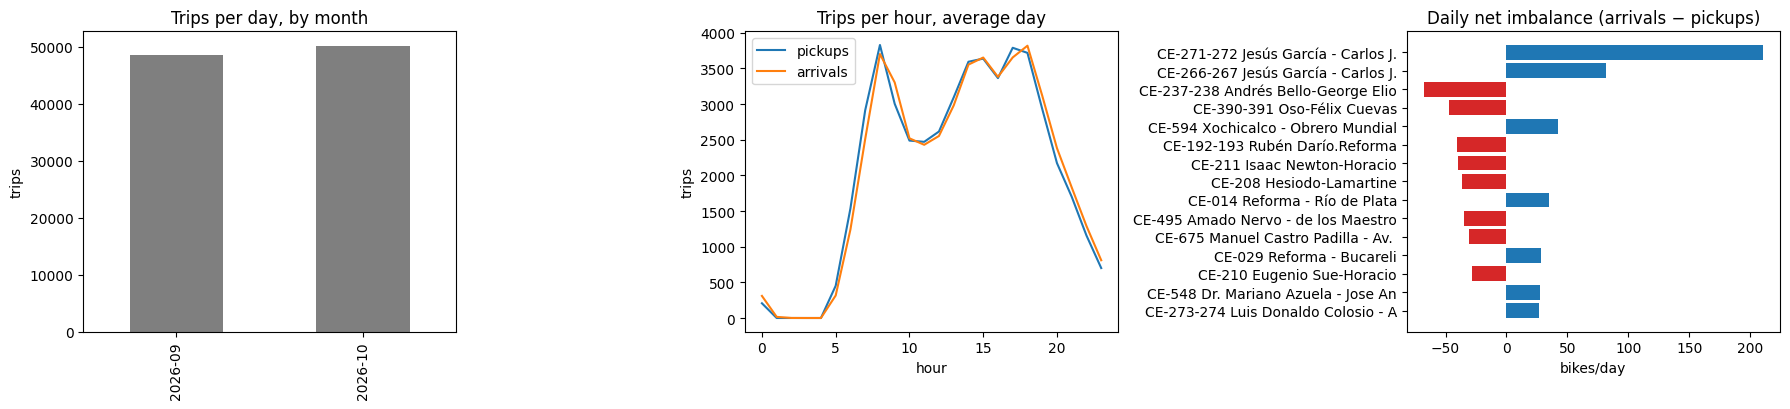

,trips per day,days
2026-09,48559.0,30
2026-10,50181.0,31


In [7]:
monthly = (pd.Series(dep.sum((1, 2)), index=days)
             .groupby(days.to_period("M")).agg(["mean", "size"])
             .rename(columns={"mean": f"trips per {DAY_WORD}", "size": f"{DAY_WORD}s"}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
monthly[f"trips per {DAY_WORD}"].plot(kind="bar", ax=axes[0], color="tab:gray")
axes[0].set(title=f"Trips per {DAY_WORD}, by month", xlabel="", ylabel="trips")
axes[0].tick_params(axis="x", labelrotation=90)

hours = np.arange(24)
axes[1].plot(hours, dep.sum(2).mean(0), label="pickups")
axes[1].plot(hours, arr.sum(2).mean(0), label="arrivals")
axes[1].set(title=f"Trips per hour, average {DAY_WORD}", xlabel="hour", ylabel="trips")
axes[1].legend()

top = st.reindex(st.net_day.abs().sort_values(ascending=False).index[:15])
axes[2].barh(top.name.str[:35], top.net_day, color=np.where(top.net_day > 0, "tab:blue", "tab:red"))
axes[2].set(title="Daily net imbalance (arrivals − pickups)", xlabel="bikes/day")
axes[2].invert_yaxis()
plt.tight_layout(); plt.savefig(OUT_DIR / "descriptive.png", dpi=150); plt.show()
monthly.round(0)

## 4. Natural zones: Louvain communities

Undirected graph with weight `T[i,j] + T[j,i]`. Louvain groups stations with a lot of flow among themselves and little towards the outside. Communities act as **contiguous zones**: each candidate is built inside a single one.

In [8]:
W = T + T.T
np.fill_diagonal(W, 0)
G = nx.from_numpy_array(W)
communities = nx.community.louvain_communities(G, weight="weight", resolution=LOUVAIN_RESOLUTION, seed=SEED)
comm = np.empty(n, dtype=int)
for c, members in enumerate(sorted(communities, key=len, reverse=True)):
    comm[list(members)] = c
st["community"] = comm

def closure_of(S):
    S = np.asarray(S)
    internal = T[np.ix_(S, S)].sum()
    touching = out_deg[S].sum() + in_deg[S].sum() - internal
    return internal / touching if touching else np.nan

comm_tab = (st.groupby("community")
              .agg(stations=("name", "size"), trips_day=("dep_day", "sum"))
              .assign(closure=[closure_of(np.where(comm == c)[0]) for c in sorted(set(comm))]))
print(f"Modularity: {nx.community.modularity(G, communities, weight='weight'):.3f}")
comm_tab

Modularity: 0.428


,stations,trips_day,closure
community,,,
0,266,13750.147541,0.701046
1,145,9536.606557,0.505987
2,140,12898.590164,0.453782
3,125,13197.786885,0.465980


## 5. Candidate subnetworks (greedy growth)

Starting from **every station** as a seed, the station most "tied" to the current set is added one at a time:

$$\text{affinity}_j = \frac{(\text{trips between } j \text{ and } S)^2}{\text{total trips of } j}$$

This rewards *j* having many trips with *S* **and** a high share of its trips going to *S* (it avoids adding a hub that only brings external flow). Constraints: same community as the seed and within `MAX_RADIUS_KM` of it (OSRM road distance, average of both directions; straight line if the file is missing). Each candidate grows to `K_TARGET` stations and duplicates are removed.

In [9]:
vol = out_deg + in_deg

def grow(seed, K=K_TARGET):
    allowed = (comm == comm[seed]) & (D[seed] <= MAX_RADIUS_KM)
    S = [seed]
    inS = np.zeros(n, bool); inS[seed] = True
    link = W[seed].copy()
    while len(S) < K:
        aff = np.where(allowed & ~inS & (vol > 0), link ** 2 / np.maximum(vol, 1), -1)
        j = int(aff.argmax())
        if aff[j] <= 0:
            break
        S.append(j); inS[j] = True
        link += W[j]
    return tuple(sorted(S))

cands = {grow(s) for s in range(n)}
cands = [c for c in cands if K_MIN <= len(c) <= K_MAX]
print(f"{len(cands)} distinct candidates with {K_MIN}–{K_MAX} stations")

370 distinct candidates with 10–15 stations


## 6. Metrics for each candidate

| Metric | What it measures | Why it matters for the model |
|---|---|---|
| `closure` | internal trips ÷ trips touching the subnetwork | How much of λ_j is explained by Σ μ_i P_ij; the rest goes to the "outside" state |
| `irreducible`, `n_scc` | can every station reach every other through arcs with ≥ `EDGE_MIN_TRIPS` trips? | The chain must be a single communicating class |
| `imbalance` | Σ \|arrivals − pickups\| per hour ÷ trips | Without imbalance there is nothing to redistribute |
| `pressure` | daily range of cumulative inventory ÷ capacity, averaged | How many times the capacity "moves" in a day: risk of emptying or filling up |
| `am_pm_inversion` | correlation between stations' AM net and PM net | Negative = commuter pattern (source in the morning, sink in the evening) |
| `excess_zeros` | observed P(0 pickups in the hour) − expected under Poisson, at peak hours | Censoring signal: hours without pickups at stations that usually have demand suggest they were **empty** |
| `min_group` | internal trips of the smallest (gender × age) group | Support for the outlier analysis by group |
| `stability` | Spearman correlation of each station's daily net flow, 2025 vs 2026 | Is the pattern we rely on stable? |

In [10]:
from scipy.stats import spearmanr

dep_mean, arr_mean = dep.mean(0), arr.mean(0)          # (24, n) average per day
net_h = arr_mean - dep_mean
lam_dep = dep_mean
zero_obs = (dep == 0).mean(0)                           # (24, n)
zero_exp = np.exp(-lam_dep)
PEAK = list(AM_HOURS) + list(PM_HOURS)

y_list = sorted(net_by_year)

def evaluate(S):
    S = np.asarray(S)
    sub = T[np.ix_(S, S)]
    internal = sub.sum()
    touching = out_deg[S].sum() + in_deg[S].sum() - internal

    A = (sub >= EDGE_MIN_TRIPS).astype(int); np.fill_diagonal(A, 0)
    Gd = nx.from_numpy_array(A, create_using=nx.DiGraph)
    n_scc = nx.number_strongly_connected_components(Gd)

    nh = net_h[:, S]
    cum = np.cumsum(np.roll(nh, -5, axis=0), axis=0)   # the operating day starts at 05:00
    swing = cum.max(0) - cum.min(0)
    cap = st.capacity.to_numpy()[S]

    am, pm = st.net_am.to_numpy()[S], st.net_pm.to_numpy()[S]
    inv = np.corrcoef(am, pm)[0, 1] if am.std() > 0 and pm.std() > 0 else np.nan

    busy = lam_dep[np.ix_(PEAK, S)] >= 1.0             # cells with >= 1 expected pickup
    excess = (zero_obs[np.ix_(PEAK, S)] - zero_exp[np.ix_(PEAK, S)])[busy]

    min_grp = int(T_grp[:, S][:, :, S].sum((1, 2)).min())

    stab = (spearmanr(net_by_year[y_list[0]][S], net_by_year[y_list[-1]][S]).statistic
            if len(y_list) > 1 else np.nan)

    iu = np.triu_indices(len(S), 1)
    return dict(
        n=len(S),
        trips_day=touching / N_DAYS,
        internal_day=internal / N_DAYS,
        closure=internal / touching,
        irreducible=n_scc == 1,
        n_scc=n_scc,
        arc_density=A.sum() / (len(S) * (len(S) - 1)),
        imbalance=np.abs(nh).sum() / (dep_mean[:, S].sum() + arr_mean[:, S].sum()),
        pressure=float(np.mean(swing / cap)),
        am_pm_inversion=inv,
        excess_zeros=float(excess.mean()) if excess.size else np.nan,
        min_group=min_grp,
        stability=stab,
        diameter_km=D[np.ix_(S, S)][iu].max(),
        capacity=int(cap.sum()),
        community=int(comm[S[0]]),
    )

metrics = pd.DataFrame([evaluate(c) for c in cands])
metrics["stations"] = [tuple(st.index[list(c)]) for c in cands]
metrics.describe().T

,count,mean,std,min,25%,50%,75%,max
n,370.0,12.000000,0.000000,12.000000,12.000000,12.000000,12.000000,12.000000
trips_day,370.0,1929.212096,887.821641,716.770492,1323.934426,1704.450820,2420.540984,4460.770492
internal_day,370.0,243.327027,82.434859,91.245902,172.815574,232.696721,299.618852,454.491803
closure,370.0,0.136400,0.038597,0.062765,0.102623,0.126618,0.162458,0.283661
n_scc,370.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
arc_density,370.0,0.967895,0.046498,0.712121,0.954545,0.984848,1.000000,1.000000
imbalance,370.0,0.163088,0.055023,0.063846,0.117280,0.159785,0.196440,0.281949
pressure,370.0,0.560786,0.273241,0.164334,0.372552,0.477209,0.742902,1.260177
am_pm_inversion,370.0,-0.650774,0.358370,-0.984885,-0.903741,-0.763553,-0.569899,0.735667
excess_zeros,370.0,0.059598,0.015259,0.029564,0.050052,0.057960,0.068285,0.115963


## 7. Three contrasting profiles

Metrics are combined as percentile ranks (0–1, across candidates) so their scales are comparable:

* **A · Closed and balanced** (baseline, where the model should fit best): high closure, low imbalance and pressure.
* **B · Commuter / imbalanced** (where the policy matters most): strong imbalance, pressure and AM/PM inversion, with reasonable closure.
* **C · Open / hub** (tests the limits of the model): high volume and a lot of flow to the outside.

Hard filters for all three: irreducible and `min_group >= MIN_TRIPS_PER_GROUP`. The best candidate of each profile is picked **with no overlap** with those already chosen. The top 10 of each profile are also saved in case you want to pick a different one.

In [11]:
r = metrics.rank(pct=True, numeric_only=True)
metrics["score_A"] = r.closure + (1 - r.imbalance) + (1 - r.pressure) + 0.5 * r.trips_day
metrics["score_B"] = r.imbalance + r.pressure + (1 - r.am_pm_inversion.fillna(0.5)) + 0.5 * r.closure + 0.5 * r.excess_zeros.fillna(0.5)
metrics["score_C"] = (1 - r.closure) + r.trips_day + 0.5 * r.pressure

eligible = metrics.irreducible & (metrics.min_group >= MIN_TRIPS_PER_GROUP)
print(f"Candidates passing the hard filters: {eligible.sum()} of {len(metrics)}")

PROFILES = {
    "A": "Closed and balanced",
    "B": "Commuter / imbalanced",
    "C": "Open / hub",
}
chosen, used = {}, set()
for p in PROFILES:
    for pool, note in [(eligible, ""), (metrics.irreducible, " (without the demographic filter)"), (metrics.n > 0, " (without hard filters)")]:
        ranked = metrics[pool].sort_values(f"score_{p}", ascending=False)
        pick = next((i for i, row in ranked.iterrows() if used.isdisjoint(row.stations)), None)
        if pick is not None:
            break
    ranked.head(10).to_csv(OUT_DIR / f"top10_profile_{p}.csv", index=False)
    if pick is None:
        print(f"Profile {p}: no disjoint candidate available")
        continue
    if note:
        print(f"Warning: profile {p} was chosen{note}; check the parameters")
    chosen[p] = pick
    used |= set(metrics.loc[pick, "stations"])

cols = ["n", "trips_day", "internal_day", "closure", "irreducible", "imbalance", "pressure",
        "am_pm_inversion", "excess_zeros", "min_group", "stability", "diameter_km", "capacity"]
summary = metrics.loc[list(chosen.values()), cols].copy()
summary.index = [f"{p} · {PROFILES[p]}" for p in chosen]
summary.round(3)

Candidates passing the hard filters: 297 of 370


,n,trips_day,internal_day,closure,irreducible,imbalance,pressure,am_pm_inversion,excess_zeros,min_group,stability,diameter_km,capacity
A · Closed and balanced,12,1399.820,180.525,0.129,True,0.087,0.164,-0.440,0.073,482,NaN,1.458,324
B · Commuter / imbalanced,12,1904.508,263.852,0.139,True,0.264,1.109,-0.833,0.082,346,NaN,1.969,310
C · Open / hub,12,4440.311,379.262,0.085,True,0.230,1.211,-0.944,0.038,585,NaN,3.066,415


In [12]:
for p, i in chosen.items():
    S = list(metrics.loc[i, "stations"])
    print(f"\n{p} · {PROFILES[p]}")
    display(st.loc[S, ["name", "capacity", "dep_day", "arr_day", "net_day", "net_am", "net_pm"]].round(1))


A · Closed and balanced


,name,capacity,dep_day,arr_day,net_day,net_am,net_pm
station,,,,,,,
337,CE-337 San Borja-Martín Mendalde,19,68.6,68.6,0.0,-2.1,0.2
356,CE-356 Matías Romero -Adolfo Prieto,15,60.0,59.8,-0.2,-0.0,-0.5
357,CE-357 Matías Romero -Amores,27,56.0,55.3,-0.7,0.2,0.1
359,CE-359 Matías Romero -Pestalozzi,31,79.7,76.0,-3.7,-3.8,0.0
360,CE-360 Heriberto Frías-Matias Romero,23,53.5,49.8,-3.8,-4.5,1.7
372,CE-372 Dr. Roberto Gayol-Tlacoquemécatl,19,101.3,103.1,1.8,0.3,1.3
373,CE-373 Pilares-Gabriel Mancera,19,48.4,47.8,-0.5,-1.1,-0.2
377,CE-377 Heriberto Frías-Miguel Laurent,35,87.2,91.1,3.9,-0.1,0.7
393,CE-393 Adolfo Prieto-Félix Cuevas,35,67.9,65.2,-2.7,-1.7,0.2



B · Commuter / imbalanced


,name,capacity,dep_day,arr_day,net_day,net_am,net_pm
station,,,,,,,
199,CE-199 Anatole France-Av. Ejército Nacional,23,33.0,31.0,-2.0,9.5,-6.2
202,CE-202 Calderón de la Barca-Av. Homero,19,35.9,32.3,-3.6,9.9,-6.2
203,CE-203 Tennyson-Av. Homero,23,36.8,30.6,-6.2,4.1,-6.7
204,CE-204 Temístocles-Homero,27,71.6,49.9,-21.7,-19.2,-6.3
206,CE-206 Homero-Moliere,23,98.0,100.1,2.1,21.2,-9.2
207,CE-207 Torquato Tasso-Homero,23,68.0,74.2,6.2,20.5,-12.1
208,CE-208 Hesiodo-Lamartine,25,248.0,211.8,-36.1,-44.0,1.1
210,CE-210 Eugenio Sue-Horacio,27,76.5,48.1,-28.3,-17.4,-7.7
211,CE-211 Isaac Newton-Horacio,35,122.2,82.2,-40.0,-33.5,-4.6



C · Open / hub


,name,capacity,dep_day,arr_day,net_day,net_am,net_pm
station,,,,,,,
014,CE-014 Reforma - Río de Plata,39,208.8,244.0,35.2,64.6,-22.2
015,CE-015 Reforma - Río Mississippi,23,137.0,145.9,8.9,25.3,-11.0
017,CE-017 Reforma - Río Tiber,27,160.4,170.6,10.2,31.9,-17.8
019,CE-019 Reforma - Río Rhin,31,144.2,128.8,-15.4,18.4,-23.5
020,CE-020 Reforma- Río Támesis,23,110.3,108.0,-2.3,1.6,-4.2
027,CE-027 Reforma- Havre,43,267.3,274.1,6.9,35.8,-22.5
028,CE-028 Toledo- Tokio,35,197.2,205.3,8.1,19.0,-8.3
031,CE-031 Hamburgo - Insurgentes,37,194.4,205.5,11.0,14.2,-7.0
041,CE-041 Reforma - Av. de la República,33,165.6,172.2,6.5,-2.7,3.7


## 8. Map

Generates `station_selection/subnetworks_map.html` (Leaflet, opens in any browser). Layers:

* all stations, coloured by Louvain community;
* each chosen subnetwork with its outline, stations (size = trips/day, blue border = receives more bikes than it lends in the morning, red = lends more) and the strongest internal flows;
* a panel with each subnetwork's metrics.

In [13]:
COLORS = {"A": "#1b7837", "B": "#c51b7d", "C": "#2166ac"}

def hull(points):
    pts = sorted(map(tuple, points))
    if len(pts) < 3:
        return pts
    def cross(o, a, b):
        return (a[0]-o[0])*(b[1]-o[1]) - (a[1]-o[1])*(b[0]-o[0])
    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0: lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0: upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]

palette = plt.get_cmap("tab20")
all_pts = [dict(lat=r.lat, lon=r.lon, name=r.name, c=int(r.community),
                color="#%02x%02x%02x" % tuple(int(255*v) for v in palette(int(r.community) % 20)[:3]))
           for r in st.itertuples()]

layers = []
for p, i in chosen.items():
    S_ids = list(metrics.loc[i, "stations"])
    S = [idx[s] for s in S_ids]
    sub = st.loc[S_ids]
    flows = []
    Tsub = T[np.ix_(S, S)] + T[np.ix_(S, S)].T
    iu = np.triu_indices(len(S), 1)
    order = np.argsort(Tsub[iu])[::-1][:20]
    for k in order:
        a_, b_ = iu[0][k], iu[1][k]
        if Tsub[a_, b_] > 0:
            flows.append(dict(a=[sub.lat.iloc[a_], sub.lon.iloc[a_]], b=[sub.lat.iloc[b_], sub.lon.iloc[b_]],
                              w=float(Tsub[a_, b_] / N_DAYS)))
    m = metrics.loc[i]
    layers.append(dict(
        key=p, label=f"{p} · {PROFILES[p]}", color=COLORS[p],
        hull=[[la, lo] for la, lo in hull(zip(sub.lat, sub.lon))],
        stations=[dict(lat=r.lat, lon=r.lon, name=r.name, cap=int(r.capacity), dep=round(r.dep_day, 1),
                       arr=round(r.arr_day, 1), am=round(r.net_am, 1), pm=round(r.net_pm, 1))
                  for r in sub.itertuples()],
        flows=flows,
        metrics={"Stations": int(m.n), "Trips/day": round(m.trips_day), "Closure": f"{m.closure:.0%}",
                 "Irreducible": "yes" if m.irreducible else "no", "Imbalance": f"{m.imbalance:.2f}",
                 "Pressure": f"{m.pressure:.2f}", "AM/PM inversion": f"{m.am_pm_inversion:.2f}",
                 "Excess zeros": f"{m.excess_zeros:.3f}", "Stability": f"{m.stability:.2f}",
                 "Diameter": f"{m.diameter_km:.1f} km ({DIST_SOURCE})"},
    ))

HTML = '''<!DOCTYPE html><html lang="en"><head><meta charset="utf-8">
<title>Ecobici subnetworks __PERIOD__</title>
<meta name="viewport" content="width=device-width, initial-scale=1">
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<style>
 html,body{margin:0;height:100%;font-family:system-ui,sans-serif}
 #map{position:absolute;inset:0 340px 0 0}
 #panel{position:absolute;top:0;right:0;width:340px;bottom:0;overflow:auto;padding:14px;box-sizing:border-box;background:#fafafa;border-left:1px solid #ddd;font-size:13px}
 h1{font-size:16px;margin:0 0 4px} .sub{color:#666;margin-bottom:12px}
 .card{background:#fff;border:1px solid #e3e3e3;border-left:5px solid;border-radius:6px;padding:8px 10px;margin-bottom:10px;cursor:pointer}
 .card h2{font-size:14px;margin:0 0 6px} table{border-collapse:collapse;width:100%} td{padding:2px 0} td:last-child{text-align:right;font-variant-numeric:tabular-nums}
 .legend{font-size:12px;color:#444;line-height:1.5}
</style></head><body>
<div id="map"></div>
<div id="panel"><h1>Candidate subnetworks</h1><div class="sub">__DAYS__, __PERIOD__ · click a card to zoom in</div>
<div id="cards"></div>
<div class="legend"><b>How to read it</b><br>Dot size = trips/day.<br>Blue border = in the morning it receives more bikes than it lends (fills up); red = lends more (empties).<br>Lines = strongest internal flows (width = trips/day in both directions).<br>Small dots = other stations, colour = Louvain community.</div>
</div>
<script>
const ALL = __ALL__; const LAYERS = __LAYERS__;
const map = L.map('map');
L.tileLayer('https://{s}.basemap.cartocdn.com/light_all/{z}/{x}/{y}{r}.png',{attribution:'&copy; OpenStreetMap &copy; CARTO',maxZoom:19}).addTo(map);
const base = L.layerGroup(ALL.map(p=>L.circleMarker([p.lat,p.lon],{radius:3,weight:0,fillColor:p.color,fillOpacity:.7}).bindTooltip(p.name+' · community '+p.c))).addTo(map);
const overlays = {'All stations (communities)': base}; const bounds = {};
const maxDep = Math.max(...LAYERS.flatMap(l=>l.stations.map(s=>s.dep+s.arr)));
LAYERS.forEach(l=>{
  const g = L.layerGroup();
  L.polygon(l.hull,{color:l.color,weight:2,fillOpacity:.08}).addTo(g);
  const wmax = Math.max(...l.flows.map(f=>f.w),1);
  l.flows.forEach(f=>L.polyline([f.a,f.b],{color:l.color,weight:1+5*f.w/wmax,opacity:.55}).bindTooltip(f.w.toFixed(1)+' trips/day').addTo(g));
  l.stations.forEach(s=>{
    const r = 5 + 13*Math.sqrt((s.dep+s.arr)/maxDep);
    L.circleMarker([s.lat,s.lon],{radius:r,color:s.am>=0?'#2166ac':'#b2182b',weight:3,fillColor:l.color,fillOpacity:.85})
     .bindPopup(`<b>${s.name}</b><br>Capacity: ${s.cap}<br>Pickups/day: ${s.dep} · Arrivals/day: ${s.arr}<br>AM net: ${s.am} · PM net: ${s.pm}`).addTo(g);
  });
  g.addTo(map); overlays[l.label] = g; bounds[l.key] = L.latLngBounds(l.stations.map(s=>[s.lat,s.lon])).pad(.3);
  const rows = Object.entries(l.metrics).map(([k,v])=>`<tr><td>${k}</td><td>${v}</td></tr>`).join('');
  const card = document.createElement('div'); card.className='card'; card.style.borderLeftColor=l.color;
  card.innerHTML = `<h2>${l.label}</h2><table>${rows}</table>`; card.onclick=()=>map.fitBounds(bounds[l.key]);
  document.getElementById('cards').appendChild(card);
});
L.control.layers(null, overlays, {collapsed:false}).addTo(map);
map.fitBounds(L.latLngBounds(LAYERS.flatMap(l=>l.stations.map(s=>[s.lat,s.lon]))).pad(.25));
</script></body></html>'''

PERIOD_LABEL = f"{days[0]:%b %Y} – {days[-1]:%b %Y}"
html = (HTML.replace("__PERIOD__", PERIOD_LABEL).replace("__DAYS__", "Weekdays" if WEEKDAYS_ONLY else "All days")
            .replace("__ALL__", json.dumps(all_pts, ensure_ascii=False))
            .replace("__LAYERS__", json.dumps(layers, ensure_ascii=False, default=float)))
map_path = OUT_DIR / "subnetworks_map.html"
map_path.write_text(html, encoding="utf-8")
print(f"Map saved to {map_path.resolve()}")

Map saved to C:\Users\axely\OneDrive\Escritorio\EcobiciMarkovChain\markovian_CDMX_ecobici_optimization\station_selection\subnetworks_map.html


Static version of the map (for the report or the presentation):

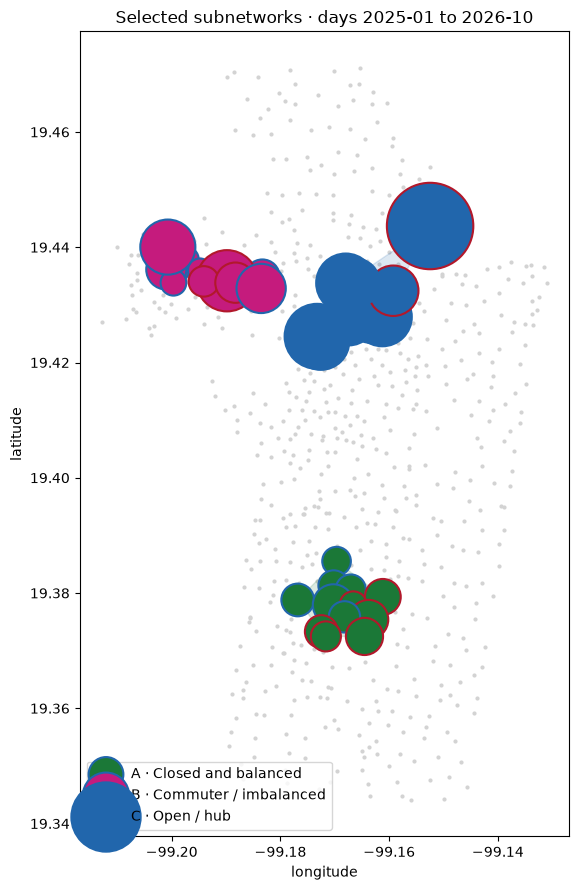

In [18]:
fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(st.lon, st.lat, s=4, c="lightgrey")
for p, i in chosen.items():
    sub = st.loc[list(metrics.loc[i, "stations"])]
    h = hull(zip(sub.lon, sub.lat))
    ax.fill(*zip(*h), color=COLORS[p], alpha=.15)
    ax.scatter(sub.lon, sub.lat, s=20 + 4 * (sub.dep_day + sub.arr_day), color=COLORS[p],
               edgecolor=np.where(sub.net_am >= 0, "#2166ac", "#b2182b"), linewidth=1.5, label=f"{p} · {PROFILES[p]}")
ax.set_aspect(1 / np.cos(np.radians(st.lat.mean())))
ax.set(title=f"Selected subnetworks · {DAY_WORD}s {days[0]:%Y-%m} to {days[-1]:%Y-%m}", xlabel="longitude", ylabel="latitude")
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(OUT_DIR / "subnetworks_map.png", dpi=170); plt.show()

## 9. Hourly profiles of each subnetwork

Pickups vs. arrivals per hour (summed over the subnetwork) and each station's cumulative inventory from 05:00 relative to its capacity. Curves going above 1 or below −1 show stations that cannot absorb the day on their own without redistribution.

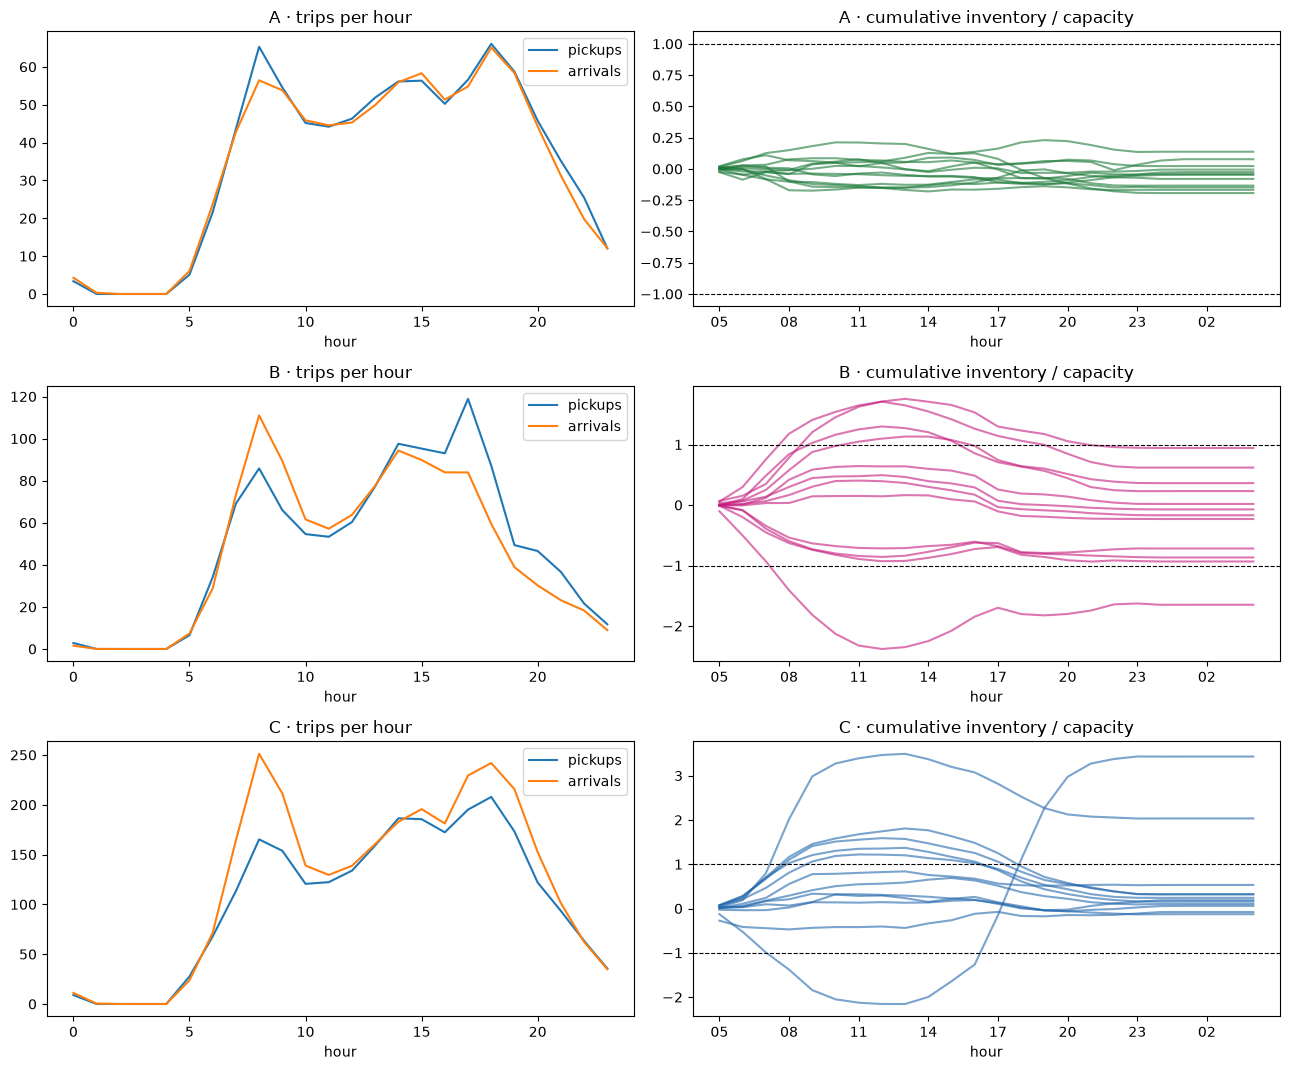

In [19]:
hours_op = np.roll(np.arange(24), -5)
fig, axes = plt.subplots(len(chosen), 2, figsize=(13, 3.6 * len(chosen)), squeeze=False)
for row, (p, i) in enumerate(chosen.items()):
    S = [idx[s] for s in metrics.loc[i, "stations"]]
    axes[row, 0].plot(np.arange(24), dep_mean[:, S].sum(1), label="pickups")
    axes[row, 0].plot(np.arange(24), arr_mean[:, S].sum(1), label="arrivals")
    axes[row, 0].set(title=f"{p} · trips per hour", xlabel="hour"); axes[row, 0].legend()
    cum = np.cumsum(net_h[hours_op][:, S], axis=0) / st.capacity.to_numpy()[S]
    axes[row, 1].plot(np.arange(24), cum, color=COLORS[p], alpha=.6)
    axes[row, 1].axhline(1, ls="--", c="k", lw=.8); axes[row, 1].axhline(-1, ls="--", c="k", lw=.8)
    axes[row, 1].set_xticks(range(0, 24, 3), [f"{h:02d}" for h in hours_op[::3]])
    axes[row, 1].set(title=f"{p} · cumulative inventory / capacity", xlabel="hour")
plt.tight_layout(); plt.savefig(OUT_DIR / "subnetwork_profiles.png", dpi=150); plt.show()

## 10. Export for the model

For each subnetwork a JSON file is saved with what both layers need:

* `stations`: id, name, coordinates, capacity.
* `mu[h][i]`: pickups per hour at station *i* (all trips, including those leaving the subnetwork) → **death** rate.
* `lam[h][j]`: arrivals per hour at *j* (all) → observed **birth** rate.
* `lam_outside[h][j]`: arrivals per hour at *j* coming from outside the subnetwork.
* `P`: routing matrix `(n+1)×(n+1)`; the last state is **"outside"**. `P[i, j]` = share of pickups at *i* that end at *j*.
* `dist_km[i][j]`: road distance from *i* to *j* (OSRM, bicycle profile; asymmetric because of one-way streets). Useful for speeds and for the outlier analysis.

With this, the relation λ_j ≈ Σ μ_i P_ij + λ_j^outside can be checked directly.

In [20]:
for p, i in chosen.items():
    S_ids = list(metrics.loc[i, "stations"])
    S = [idx[s] for s in S_ids]
    k = len(S)
    Tk = np.zeros((k + 1, k + 1))
    Tk[:k, :k] = T[np.ix_(S, S)]
    Tk[:k, k] = out_deg[S] - T[np.ix_(S, S)].sum(1)
    Tk[k, :k] = in_deg[S] - T[np.ix_(S, S)].sum(0)
    P = Tk / np.maximum(Tk.sum(1, keepdims=True), 1)

    notS = np.setdiff1d(np.arange(n), S)
    lam_out = T_harr[:, notS][:, :, S].sum(1) / N_DAYS      # (24, k) arrivals from outside per hour

    payload = dict(
        profile=p, label=PROFILES[p], period=[str(days[0].date()), str(days[-1].date())], weekdays_only=WEEKDAYS_ONLY, n_days=N_DAYS,
        stations=[dict(id=s, name=r.name, lat=r.lat, lon=r.lon, capacity=int(r.capacity))
                  for s, r in st.loc[S_ids].iterrows()],
        mu=dep_mean[:, S].round(4).tolist(),
        lam=arr_mean[:, S].round(4).tolist(),
        lam_outside=lam_out.round(4).tolist(),
        P=P.round(6).tolist(),
        dist_km=D_dir[np.ix_(S, S)].round(3).tolist(),   # i -> j, by road if OSRM is available
        dist_source=DIST_SOURCE,
        state_labels=S_ids + ["outside"],
        metrics={k_: (v.item() if hasattr(v, "item") else v) for k_, v in metrics.loc[i, cols].items()},
    )
    path = OUT_DIR / f"subnetwork_{p}.json"
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{p}: {path}  · P row 'outside'→subnetwork sums to {P[k, :k].sum():.2f}")

metrics.drop(columns=[c for c in metrics if c.startswith("score")]).to_csv(OUT_DIR / "candidate_metrics.csv", index=False)

A: station_selection\subnetwork_A.json  · P row 'outside'→subnetwork sums to 1.00
B: station_selection\subnetwork_B.json  · P row 'outside'→subnetwork sums to 1.00
C: station_selection\subnetwork_C.json  · P row 'outside'→subnetwork sums to 1.00


## 11. How to defend the selection (Activity 1)

* **Period:** all days of the 22 months (Jan-2025 to Oct-2026), weekends included for now (`WEEKDAYS_ONLY = False`); the challenge asks for weekdays, so switch it to `True` before the final analysis. The monthly volume chart shows seasonality; the `stability` column compares each station's imbalance in 2025 vs 2026.
* **Cleaning:** table in section 3 (`cleaning_log.csv`).
* **Subnetwork:** not chosen by eye; stations come from flow communities (Louvain) and a reproducible greedy growth. The subnetwork is irreducible (a single communicating class) and has a measured closure; whatever does not close enters the model as the "outside" state.
* **Censoring:** `excess_zeros` measures peak hours without pickups at stations where Poisson would almost never allow a zero. If it is high, observed demand is **underestimated** at those stations: they are the ones that fail, not the ones with low demand.
* **Comparison:** A, B and C show where the model describes the system well (A), where a policy has the most impact (B) and where it stops being a good description (C).

> Note on closure: in a system where trips average 2–3 km, a 12-station subnetwork spanning ~2 km rarely closes more than 30–40 %. Rather than hitting a fixed threshold, what matters is that the "outside" state is modelled explicitly.